### In this notebook I tried a different approach with combining the datasets and did some EDA with the whole set

In [2]:
# IMPORTS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score

In [ ]:
# Combining the datasets together with a new column for run_id and road_id

dfA1 = pd.read_csv("../dataset/cleaned/Iisingintie0.csv")
dfA2 = pd.read_csv("../dataset/cleaned/Iisingintie1.csv")
dfA3 = pd.read_csv("../dataset/cleaned/Iisingintie2.csv")

dfB1 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie0.csv")
dfB2 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie1.csv")
dfB3 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie2.csv")
dfB4 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie3.csv")

dfC1 = pd.read_csv("../dataset/cleaned/Kaittiaisentie1.csv")


runs = {
    "A1": (dfA1, "A"), "A2": (dfA2, "A"), "A3": (dfA3, "A"),
    "B1": (dfB1, "B"), "B2": (dfB2, "B"), "B3": (dfB3, "B"), "B4": (dfB4, "B"),
    # "C1": (dfC1, "C"),
}

df = pd.concat(
    [d.assign(run_id=rid, road_id=road) for rid, (d, road) in runs.items()],
    ignore_index=True,
)

In [4]:
run_names = list(runs.keys())
print(run_names)

['A1', 'A2', 'A3', 'B1', 'B2', 'B3', 'B4']


In [5]:
df

,Timer(ms),Loc(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,AccY,AccZ,GyrX,GyrY,GyrZ,Speed_kmh,Frostbumps,run_id,road_id
0,45493158.5,3850.503,106.794000,1.1747,-3.0780,141.0204,1.53481,0.05712,9.58495,0.03196,0.00072,-0.00300,62.1936,0,A1,A
1,45493161.0,3850.546,106.794000,1.2245,-3.0428,141.1350,1.51066,-0.04196,10.50449,0.02201,0.00598,-0.01390,62.2044,0,A1,A
2,45493163.5,3850.589,106.794000,1.2281,-3.0428,141.1349,1.15831,0.37071,10.76888,0.01993,0.00065,-0.00562,62.2116,0,A1,A
3,45493166.0,3850.633,106.794000,1.2330,-3.0430,141.1341,1.03301,0.31102,11.42271,0.02887,-0.00077,-0.01012,62.2224,0,A1,A
4,45493168.5,3850.676,106.794000,1.2363,-3.0431,141.1329,0.99574,-0.37334,11.76243,0.01783,0.00007,-0.01306,62.2332,0,A1,A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
300812,41563778.5,5512.852,10.355333,0.6512,-1.5795,-48.0806,-1.78920,0.16438,10.33153,-0.00936,-0.01235,-0.02487,33.9372,0,B4,B
300813,41563781.0,5512.875,11.012904,0.6481,-1.5840,-47.9881,-1.88369,-0.02342,10.76440,-0.00575,-0.00767,-0.02849,33.9372,0,B4,B
300814,41563783.5,5512.899,10.800525,0.6452,-1.5904,-47.8951,-1.92509,-0.06587,10.62556,-0.00451,-0.02198,-0.02490,33.9372,0,B4,B
300815,41563786.0,5512.922,10.374600,0.6427,-1.5977,-47.8027,-1.60182,0.24200,10.34438,-0.00214,-0.02739,-0.02887,33.9408,0,B4,B


In [6]:
feature_cols = ["AccX", "AccY", "AccZ", "GyrX", "GyrY", "GyrZ",
                "Pitch(deg)", "Roll(deg)", "Speed_kmh"]


In [7]:
# This code makes row windows of the data, with a given window size and stride. It returns the X and y values for each window.

# def make_row_windows(run_df, win=100, stride=20):
#     run_df = run_df.sort_values("Timer(ms)")
#     X = run_df[feature_cols].to_numpy(np.float32)
#     y = run_df["Frostbumps"].to_numpy()

#     X_clips, y_clips = [], []
#     for start in range(0, len(X) - win + 1, stride):
#         end = start + win
#         X_clips.append(X[start:end])
#         y_clips.append(y[start:end].max())

#     return np.array(X_clips), np.array(y_clips)

In [8]:
def make_row_windows(run_df, win=0, stride=0, min_percentage=0.1):
    run_df = run_df.sort_values("Timer(ms)")

    X = run_df[feature_cols].to_numpy(np.float32)
    y = run_df["Frostbumps"].to_numpy()

    X_clips, y_clips = [], []

    for start in range(0, len(X) - win + 1, stride):
        end = start + win

        X_clips.append(X[start:end])

        bump_percentage = y[start:end].mean()
        y_clips.append(int(bump_percentage >= min_percentage))

    return np.array(X_clips), np.array(y_clips)

In [9]:
def get_clips(run_names):
    all_X, all_y = [], []
    for name in run_names:
        one_run = df[df["run_id"] == name]
        X, y = make_row_windows(one_run, win=600, stride=400)
        all_X.append(X)
        all_y.append(y)
    return np.concatenate(all_X), np.concatenate(all_y)

In [ ]:
# Checking the number of windows per run

for run in ["A1", "A2", "A3", "B1", "B3", "B4"]:
    X, y = get_clips([run])

    print(
        f"{run}: {len(y)} windows, "
        f"{y.mean():.1%} positive"
    )

A1: 141 windows, 30.5% positive
A2: 188 windows, 26.6% positive
A3: 286 windows, 22.4% positive
B1: 23 windows, 43.5% positive
B3: 32 windows, 37.5% positive
B4: 44 windows, 38.6% positive
C1: 0 windows, nan% positive


C:\Users\Niko Vuokila\AppData\Local\Temp\ipykernel_19656\3187901650.py:8: RuntimeWarning: Mean of empty slice.
  f"{y.mean():.1%} positive"
c:\Users\Niko Vuokila\OneDrive\Työpöytä\Kouluhommat\FallProject2026\SemesterProjectFall2026\.venv\Lib\site-packages\numpy\_core\_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [11]:
# Training, validation, test splits

Xtr, ytr = get_clips(["A2", "B1", "B3", "A3"])
Xva, yva = get_clips(["B4"])
Xte, yte = get_clips(["A1"])

print(Xtr.shape, Xva.shape, Xte.shape)
print(ytr.mean(), yva.mean(), yte.mean())

(529, 600, 9) (44, 600, 9) (141, 600, 9)
0.2570888468809074 0.38636363636363635 0.3049645390070922


In [12]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

n_features = Xtr.shape[-1]      # 9 now

scaler = StandardScaler()
scaler.fit(Xtr.reshape(-1, n_features))

Xtr = scaler.transform(Xtr.reshape(-1, n_features)).reshape(Xtr.shape)
Xva = scaler.transform(Xva.reshape(-1, n_features)).reshape(Xva.shape)
Xte = scaler.transform(Xte.reshape(-1, n_features)).reshape(Xte.shape)

In [13]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=Xtr.shape[1:]),
    layers.Conv1D(16, 7, padding="same", activation="relu"),
    layers.MaxPooling1D(2),
    layers.Conv1D(32, 5, padding="same", activation="relu"),
    layers.GlobalMaxPooling1D(),
    layers.Dropout(0.3),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

optimizer = keras.optimizers.Adam(learning_rate=0.001)

model.compile(optimizer="adam", loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])

w = min((ytr == 0).sum() / max((ytr == 1).sum(), 1), 20)

history = model.fit(Xtr, ytr, validation_data=(Xva, yva),
          epochs=100, batch_size=32,
          class_weight={0: 1.0, 1: float(w)},
          callbacks=[keras.callbacks.EarlyStopping(
              monitor="val_loss", patience=10, restore_best_weights=True)])



Epoch 1/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 1.2561 - pr_auc: 0.3224 - val_loss: 0.6999 - val_pr_auc: 0.5621
Epoch 2/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.0174 - pr_auc: 0.4371 - val_loss: 0.6715 - val_pr_auc: 0.5914
Epoch 3/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9384 - pr_auc: 0.5515 - val_loss: 0.6967 - val_pr_auc: 0.5841
Epoch 4/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8706 - pr_auc: 0.6287 - val_loss: 0.6456 - val_pr_auc: 0.6083
Epoch 5/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8370 - pr_auc: 0.6514 - val_loss: 0.7424 - val_pr_auc: 0.5253
Epoch 6/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.7461 - pr_auc: 0.7497 - val_loss: 0.6537 - val_pr_auc: 0.5740
Epoch 7/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.7381 - pr_auc: 0.7103 - val_loss: 0.6985 - val_pr_auc: 0.5906
Epoch 8/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.7404 - pr_auc: 0.7310 - val_loss: 0.6516 - val_pr_auc: 0.5971
Epoch 9/100
17/

In [14]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 600, 16)        │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 300, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 300, 32)        │         2,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 32)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,485 (48.77 KB)

 Trainable params: 4,161 (16.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,324 (32.52 KB)

In [15]:
from sklearn.metrics import average_precision_score, roc_auc_score

# Get predicted probabilities
y_pred_proba = model.predict(Xte).ravel()

# Calculate AUC scores
pr_auc = average_precision_score(yte, y_pred_proba)
roc_auc = roc_auc_score(yte, y_pred_proba)

print(f"PR-AUC:  {pr_auc:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
PR-AUC:  0.8343
ROC-AUC: 0.8716


<Axes: >

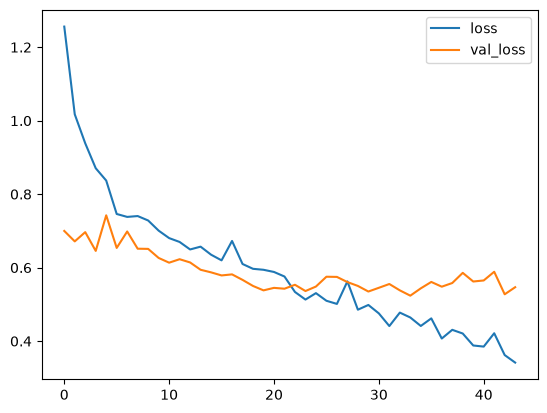

In [16]:
loss_df = pd.DataFrame(model.history.history)
loss_df[['loss', 'val_loss']].plot()

In [17]:
# compare the final model loss/accuracy/evaluation values
# the values should match mostly
print("Test data evaluation:")
print(model.evaluate(Xte, yte, verbose=0))
print("\nTrain data evaluation:")
print(model.evaluate(Xtr, ytr, verbose=0))

Test data evaluation:
[0.4310052692890167, 0.8342107534408569]

Train data evaluation:
[0.2583525776863098, 0.937692403793335]


In [18]:
test_predictions = model.predict(Xte).ravel()

test_predictions = (test_predictions >= 0.5).astype(int)


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


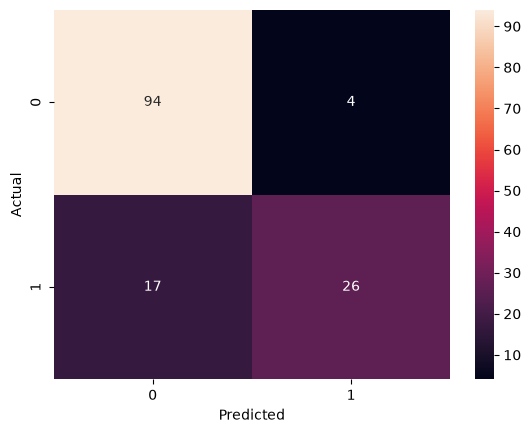

In [19]:


# confusion matrix
import seaborn as sns
sns.heatmap(confusion_matrix(yte, test_predictions), annot=True, fmt='g')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()



In [20]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = (model.predict(Xte).ravel() >= 0.6).astype(int)

print(confusion_matrix(yte, y_pred))
print(classification_report(yte, y_pred))

acc = accuracy_score(yte, test_predictions)
print("\nModel overall accuracy: {:.2f}%".format(acc * 100))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
[[94  4]
 [18 25]]
              precision    recall  f1-score   support

           0       0.84      0.96      0.90        98
           1       0.86      0.58      0.69        43

    accuracy                           0.84       141
   macro avg       0.85      0.77      0.79       141
weighted avg       0.85      0.84      0.83       141


Model overall accuracy: 85.11%


In [21]:
y_prob = model.predict(Xte).ravel()

print("Minimum:", y_prob.min())
print("Maximum:", y_prob.max())
print("Mean:", y_prob.mean())

y_pred = (y_prob >= 0.5).astype(int)

print("Predicted classes:")
print(np.unique(y_pred, return_counts=True))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
Minimum: 0.00044279275
Maximum: 0.999918
Mean: 0.2804894
Predicted classes:
(array([0, 1]), array([111,  30]))


In [22]:
y_prob = model.predict(Xte).ravel()

print("Actual frost bumps:", np.sum(yte == 1))
print("Predicted frost bumps:", np.sum(y_prob >= 0.5))

print("\nProbabilities for actual frost bumps:")
print(y_prob[yte == 1])

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Actual frost bumps: 43
Predicted frost bumps: 30

Probabilities for actual frost bumps:
[7.7571565e-01 9.9990225e-01 9.9969929e-01 1.3927348e-01 9.9950427e-01
 9.9860990e-01 6.6405308e-01 3.3259425e-01 5.5980688e-01 5.5355217e-02
 3.7905312e-01 3.6916044e-01 3.6450338e-01 8.5903883e-01 9.3065631e-01
 9.9987698e-01 9.7718859e-01 9.9930406e-01 9.9984163e-01 9.7553170e-01
 1.2626235e-01 3.9768413e-01 1.8753815e-01 4.4279275e-04 5.2400964e-04
 1.1186069e-01 6.3678706e-01 7.1536911e-01 5.4323107e-02 1.6285211e-01
 9.3766272e-02 9.9974817e-01 9.9991798e-01 9.1525412e-01 4.0164167e-01
 4.8203376e-01 9.9756539e-01 9.9633294e-01 9.6581501e-01 9.5167744e-01
 9.9905431e-01 9.9988782e-01 9.4566381e-01]


In [23]:
# runs = ["A1", "A2", "A3", "B1", "B2", "B3", "B4"]

# test_run = "A1"
# val_run = "A2"
# train_runs = [r for r in runs if r not in (test_run, val_run)]

# print(train_runs)

In [24]:
# def build_model(input_shape):
#     model = keras.Sequential([
#         layers.Input(shape=input_shape),
#         layers.Conv1D(8, 7, padding="same", activation="relu"),
#         layers.MaxPooling1D(2),
#         layers.Conv1D(16, 5, padding="same", activation="relu"),
#         layers.GlobalMaxPooling1D(),
#         layers.Dropout(0.3),
#         layers.Dense(16, activation="relu"),
#         layers.Dense(1, activation="sigmoid"),
#     ])
#     model.compile(optimizer="adam", loss="binary_crossentropy")
#     return model

In [25]:
# scores = {}

# for i, test_run in enumerate(runs):
#     val_run = runs[(i + 1) % len(runs)]
#     train_runs = [r for r in runs if r not in (test_run, val_run)]

#     Xtr, ytr = get_clips(train_runs)
#     Xva, yva = get_clips([val_run])
#     Xte, yte = get_clips([test_run])

#     n_features = Xtr.shape[-1]
#     scaler = StandardScaler().fit(Xtr.reshape(-1, n_features))
#     Xtr = scaler.transform(Xtr.reshape(-1, n_features)).reshape(Xtr.shape)
#     Xva = scaler.transform(Xva.reshape(-1, n_features)).reshape(Xva.shape)
#     Xte = scaler.transform(Xte.reshape(-1, n_features)).reshape(Xte.shape)

#     keras.backend.clear_session()
#     model = build_model(Xtr.shape[1:])

#     model.fit(
#         Xtr, ytr,
#         validation_data=(Xva, yva),
#         epochs=30,
#         batch_size=32,
#         class_weight={0: 1.0, 1: 3.0},
#         verbose=0,
#         callbacks=[keras.callbacks.EarlyStopping(
#             monitor="val_loss", patience=5, restore_best_weights=True)],
#     )

#     probs = model.predict(Xte, verbose=0).ravel()
#     scores[test_run] = average_precision_score(yte, probs)
#     print(test_run, "score:", round(scores[test_run], 2),
#           "| random guess:", round(yte.mean(), 2))

# print("mean:", sum(scores.values()) / len(scores))